In [24]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [25]:
fpaths = []
labels = []
spoken = []

In [26]:
for f in os.listdir("./Audio"):
    for w in os.listdir("./Audio/" + f):
        fpaths.append("./Audio/" + f + "/" + w)
        labels.append(f)
        if f not in spoken:
            spoken.append(f)

print("Words spoken: ", spoken)
print("Labels: ", labels)
print("fpaths spoken: ", fpaths)

Words spoken:  ['apple', 'banana', 'book', 'cat', 'dog', 'eye', 'fast', 'god', 'human', 'kiwi', 'lime']
Labels:  ['apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'fast', 'fast', 'fast', 'fast',

In [27]:
from scipy.io import wavfile

In [28]:
data = np.zeros((len(fpaths), 32000))
maxsize = -1
for n, file in enumerate(fpaths):
    _, d = wavfile.read(file)
    data[n, :d.shape[0]] = d
    if d.shape[0] > maxsize:
        maxsize = d.shape[0]

data = data[:, :maxsize]

In [29]:
all_labels = np.zeros(data.shape[0])
dictionary = [""] * 14

In [30]:
for n, l in enumerate(set(labels)): 
    all_labels[np.array([i for i, value in enumerate(labels) if value == l])] = n

for i in range(0, len(all_labels)): 
    dictionary[int(all_labels[i])] = labels[i]

print("Dictionary: ", dictionary)
print("all_labels: ", all_labels)

Dictionary:  ['book', 'apple', 'dog', 'banana', 'god', 'kiwi', 'fast', 'eye', 'human', 'lime', 'cat', '', '', '']
all_labels:  [ 1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  3.  3.  3.  3.  3.  3.
  3.  3.  3.  3.  3.  3.  3.  3.  3.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10.
 10. 10. 10.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.  2.
  7.  7.  7.  7.  7.  7.  7.  7.  7.  7.  7.  7.  7.  7.  7.  6.  6.  6.
  6.  6.  6.  6.  6.  6.  6.  6.  6.  6.  6.  6.  4.  4.  4.  4.  4.  4.
  4.  4.  4.  4.  4.  4.  4.  4.  4.  8.  8.  8.  8.  8.  8.  8.  8.  8.
  8.  8.  8.  8.  8.  8.  5.  5.  5.  5.  5.  5.  5.  5.  5.  5.  5.  5.
  5.  5.  5.  9.  9.  9.  9.  9.  9.  9.  9.  9.]


In [31]:
import scipy

In [32]:
def stft(x, fftsize = 64, overlap_pct =.5):
    hop = int(fftsize * (1 - overlap_pct)) 
    w = scipy.hanning(fftsize + 1)[:-1] 
    raw = np.array([np.fft.rfft(w * x[i:i + fftsize]) for i in range(0, len(x) - fftsize,hop)]) 

    return raw[:, :(fftsize // 2)]

In [33]:
from scipy.signal.windows import hann

In [34]:
def stft(x, fftsize = 64, overlap_pct =.5):
    hop = int(fftsize * (1 - overlap_pct)) 
    w = hann(fftsize + 1)[:-1] 
    raw = np.array([np.fft.rfft(w * x[i:i + fftsize]) for i in range(0, len(x) - fftsize,hop)]) 

    return raw[:, :(fftsize // 2)]

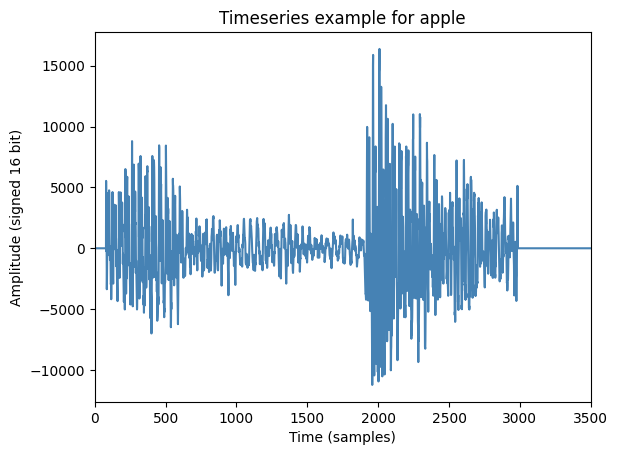

In [35]:
plt.plot(data[0, :], color="steelblue")
plt.title("Timeseries example for %s" %labels[0])
plt.xlim(0, 3500)
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude (signed 16 bit)")
plt.show()

In [36]:
from numpy.lib.stride_tricks import as_strided

In [37]:
def peakfind(x, n_peaks, l_size = 3, r_size = 3, c_size = 3, f=np.mean):
    win_size = l_size + r_size + c_size
    shape = x.shape[:-1] + (x.shape[-1] - win_size + 1, win_size) 

    strides = x.strides + (x.shape[-1], ) 
    xs = as_strided(x, shape = shape, strides = strides) 

    def is_peak(x):
        centered = (np.argmax(x) == l_size + int(c_size / 2)) 

        l = x[:l_size]
        c = x[l_size:l_size + c_size]
        r = x[-r_size:]

        passes = np.max(c) > np.max([f(l), f(r)]) 
        if centered and passes:
            return np.max(c)
        else:
            return -1

    r = np.apply_along_axis(is_peak, 1, xs) 
    top = np.argsort(r, None)[::-1] 
    heights = r[top[:n_peaks]] 
    top[top > -1] = top[top > -1] + l_size + int(c_size / 2.) 
    return heights, top[:n_peaks]

In [38]:
all_obs = []
for i in range(data.shape[0]): 
    d = np.abs(stft(data[i, :]))
    n_dim = 6 
    obs = np.zeros((n_dim, d.shape[0]))

    for r in range(d.shape[0]):
        _, t = peakfind(d[r, :], n_peaks = n_dim)
        obs[:, r] = t.copy()

    if i % 10 == 0:
        print("Processed obs %s" %i)
    all_obs.append(obs)

all_obs = np.atleast_3d(all_obs) 

Processed obs 0
Processed obs 10
Processed obs 20
Processed obs 30
Processed obs 40
Processed obs 50
Processed obs 60
Processed obs 70
Processed obs 80
Processed obs 90
Processed obs 100
Processed obs 110
Processed obs 120
Processed obs 130
Processed obs 140
Processed obs 150
Processed obs 160
Processed obs 170


Membuat class GMM dan HMM yang akan digunakan untuk klasifikasi audio-audio kita.

In [39]:
import scipy.stats as st 
from scipy.stats import multivariate_normal 

In [40]:
class gmmhmm:
    def __init__(self, n_states):
        self.n_states = n_states
        self.random_state = np.random.RandomState(0)
        self.prior = self._normalize(self.random_state.rand(self.n_states, 1))
        self.A = self._stochasticize(self.random_state.rand(self.n_states, self.n_states))

        self.mu = None 
        self.covs = None 
        self.n_dims = None
        
    def _forward(self, B): 
        log_likelihood = 0 

        T = B.shape[1] 
        alpha = np.zeros(B.shape)

        for t in range(T):
            if t == 0:
                alpha[:, t] = B[:, t] * self.prior.ravel() 
            else:
                alpha[:, t] = B[:, t] * np.dot(self.A.T, alpha[:, t-1])

            alpha_sum = np.sum(alpha[:, t])
            alpha[:, t] /= alpha_sum
            log_likelihood = log_likelihood + np.log(alpha_sum)

        return log_likelihood, alpha

    def _backward(self, B):
        T = B.shape[1]
        beta = np.zeros(B.shape) 

        beta[:, -1] = np.ones(B.shape[0])
        for t in range(T - 1)[::-1]: 
            beta[:, t] = np.dot(self.A, (B[:, t + 1] * beta[:, t + 1])) 
            beta[:, t] /= np.sum(beta[:, t]) 
        return beta

    def _state_likelihood(self, obs): 
        obs = np.atleast_2d(obs) 
        B = np.zeros((self.n_states, obs.shape[1])) 
        for s in range(self.n_states): 
            np.random.seed(self.random_state.randint(1))
            B[s, :] = st.multivariate_normal.pdf(obs.T, mean = self.mu[:, s].T, cov = self.covs[:, :, s].T)
        return B

    def _normalize(self, x):
        return (x + (x == 0)) / np.sum(x)

    def _stochasticize(self, x): 
        return (x + (x == 0)) / np.sum(x, axis=1)

# === BATAS MULAI SESI 8 ===
# EM -> Rcpectation Maximization: algoritma iteratif yang memperkirakan parameter model ketika terdapat info tersembunyi
    def _em_init(self, obs):
        if self.n_dims is None:
            self.n_dims = obs.shape[0]
        
        if self.mu is None:
            subset = self.random_state.choice(np.arange(self.n_dims), size = self.n_states, replace = False)
            self.mu = obs[:, subset]
            
        if self.covs is None:
            self.covs = np.zeros((self.n_dims, self.n_dims, self.n_states))
            self.covs += np.diag(np.diag(np.cov(obs)))[:, :, None]
        
        return self
    
    # em_step -> mengambil 1 obs lalu bakal menghitung likelihood dan alpha
    def _em_step(self, obs):
        obs = np.atleast_2d(obs)
        
        # hitung likelihood
        B = self._state_likelihood(obs)
        T = obs.shape[1]
        
        log_likelihood, alpha = self._forward(B)
        beta = self._backward(B)
        
        xi_sum = np.zeros((self.n_states, self.n_states))
        gamma = np.zeros((self.n_states, T))
        
        # looping untuk tiap time stamp
        for t in range(T-1):
            partial_sum = self.A * np.dot(alpha[:, t], (beta[:, t] * B[:, t+1].T))
            xi_sum += self._normalize(partial_sum)
            partial_g = alpha[:, t] * beta[:, t]
            
            # menormalize gamma dengan function normalize
            gamma[:, t] = self._normalize(partial_g)
        
        partial_g = alpha[:, t] * beta[:, t]
        gamma[:, t] = self._normalize(partial_g)
        
        # kalkulasi prior probability yang terjadi pada kolom pertama gamma
        # expected_prior -> probabilitas awal state yang memperkirakan dari gamma pada frame pertama
        expected_prior = gamma[:, 0]
        expected_A = self._stochasticize(xi_sum)
        expected_mu = np.zeros((self.n_states, self.n_states))
        expected_covs = np.zeros((self.n_dims,self.n_dims, self.n_states))
        gamma_state_sum = np.sum(gamma, axis=1)
        gamma_states_sum = gamma_state_sum + (gamma_state_sum == 0)
        
        # looping tiap hidden state
        for s in range(self.n_states):
            gamma_obs = obs * gamma[s, :]
            expected_mu[:, s] = np.sum(gamma_obs, axis=1) / gamma_state_sum[s]
            partial_covs = np.dot(gamma_obs, obs.T) / gamma_state_sum[s] - np.dot(expected_mu[:, s], expected_mu[:, s].T)
            
            partial_covs = np.triu(partial_covs) + np.triu(partial_covs).T - np.diag(partial_covs)
        
        expected_covs += .01 * np.eye(self.n_dims)[:, :, None]
        
        self.prior = expected_prior
        self.mu = expected_mu
        self.covs = expected_covs
        self.A = expected_A
        return log_likelihood
    
    def fit(self, obs, n_iter=8):
        if len(obs.shape) ==  2:
            for i in range(n_iter):
                self._em_init(obs)
                log_likelihood = self._em_step(obs)
        
        elif len(obs.shape) == 3:
            count = obs.shape[0]
            for n in range(count):
                for i in range(n_iter):
                    self._em_init(obs[n, :, :])
                    log_likelihood = self._em_step(obs[n, :, :])
        
        return self
    
    # function Transform -> dipakai untuk melakukan klasifikasi atau hitung skor pengenalan suara
    def transform(self, obs):
        if len(obs.shape) == 2:
            # hitung likelihood
            B = self._state_likelihood(obs)
            log_likelihood, _ = self._forward(B)
            return log_likelihood
        
        elif len(obs.shape) == 3:
            count = obs.shape[0]
            out = np.zeros((count,))
            for n in range(count):
                # hitung setiap sequence
                B = self._state_likelihood(obs[n, :, :])
                log_likelihood, _ = self._forward(B)
                out[n] = log_likelihood
            return out

In [41]:
import sklearn
from sklearn.model_selection import StratifiedShuffleSplit
# bagi dataset menjadi training dan testing secara acak namun dia masih mempertahankan proporsi kelasnya

In [42]:
for n, i in enumerate(all_obs):
    all_obs[n] /= all_obs[n].sum(axis=0)

x = all_obs
y = all_labels

n_splits = np.array(np.bincount(all_labels.astype(int))).sum()
sss = StratifiedShuffleSplit(8, test_size=0.1, random_state=0)

for train_index, test_index in sss.split(x, y):
    print("TRAIN: ", train_index, "TEST: ", test_index)
    X_train, X_test = all_obs[train_index, ...], all_obs[test_index, ...]
    y_train, y_test = all_labels[train_index], all_labels[test_index]

ys = set(all_labels)
ms = [gmmhmm(6) for y in ys]

# training
_ = [m.fit(X_train[y_train == y,:,:]) for m, y in zip(ms, ys)]

# melakukan klasifikasi log_likelihood dari setiap test di vector x_test
ps = [m.transform(X_test) for m in ms]
res = np.vstack(ps)
predicted_labels = np.argmax(res, axis=0)
# dapet missed classification
missed = (predicted_labels != y_test)
print("Test Accuracy: %.2f" %(100*(1-np.mean(missed))))

TRAIN:  [139 124  42 121  70 152 101 140  87  35 129 114  10  32 112 167 106  64
  62 127   1   6 117  81 141  58 136   4  44 109  57  26 131  79  49  41
 113 154  78  30 147  37  93   3 157 166 104  61  33  40 128 156  83   2
 142  54  67 100  39  43 118  56  25 148  46  21  66  15  90 103  91  82
  63 108 145 170 137  86 155  98 135 144 123  53  20  71 172  14 160  17
  76  80  89  24 159  69  23  48   7  16  34  51 162 146   0  77 151 122
  73  65   5 119 126 107  59 149 163  74  12 150  84 171 115  55 169 153
  94  19  52  88  28  85 130 120  29  18 134 173 116 161  97  92  60  27
  96  22 133 102 143 158 168  45 111  11  36  31] TEST:  [ 38  13 164 105  50   9  75  99 165  68  47 132 138  95 110  72 125   8]
TRAIN:  [ 89  95 105 145  63  69  42  83  24  41  79  87 125 136 147  47 151 173
  88  97 163  11  68 123  81 134  52 111   1  25 143  27 119  26  22  48
  92 140 167   5  64 102  59  33 139 114 141 131  46 172  28 113  94 162
  91  21 128  20 159  55 152  19  15  45  43  30  

In [43]:
maxsize = 32000
new_data = np.zeros(maxsize)
_, new_d = wavfile.read("./Audio/apple/apple12.wav")
new_data[:new_d.shape[0]] = new_d
new_data = new_data[:maxsize]

observation = []

# kalkulasi STFT
new_d = np.abs(stft(new_data))
n_dim = 6
new_obs = np.zeros((n_dim, new_d.shape[0]))

# cari peak tertinggi PeakFind
for r in range(new_d.shape[0]):
    _, t = peakfind(new_d[r, :], n_peaks=n_dim)
    new_obs[:, r] = t.copy()
    
observation.append(new_obs)
observation = np.atleast_3d(observation)

# normalize observation
observation /= observation.sum(axis=1)
# transform observation
ps_test = [m.transform(observation) for m in ms]
res_test = np.vstack(ps_test)

# cari index maximum dari res_test dan disimpan di test predict
test_predicted_label = np.argmax(res_test, axis=0)
predicted_labels = test_predicted_label[0]
word_spoken = dictionary[predicted_labels]

print(word_spoken)

fast
